## C2 · Matplotlib: chart types and layouts

Scatter, bar, histogram, box and pie charts, then multi-panel layouts.

In [844]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

# Penguins with no missing values, so plots do not have to deal with NaN
df_complete = df_penguins.dropna()

### Scatter plots

#### Drawing a scatter plot

**C2.01**

`plt.scatter(x, y)`

The `plt.scatter(x, y)` function allows us to plot one point per observation. It is useful for seeing the relationship between two numeric variables. Alternatively, `sns.scatterplot` and `df.plot.scatter` draw from a DataFrame.

In [845]:
# display the example data
df_complete[["flipper_length_mm", "body_mass_g"]].head()

,flipper_length_mm,body_mass_g
0,181.0,3750.0
1,186.0,3800.0
2,195.0,3250.0
4,193.0,3450.0
5,190.0,3650.0


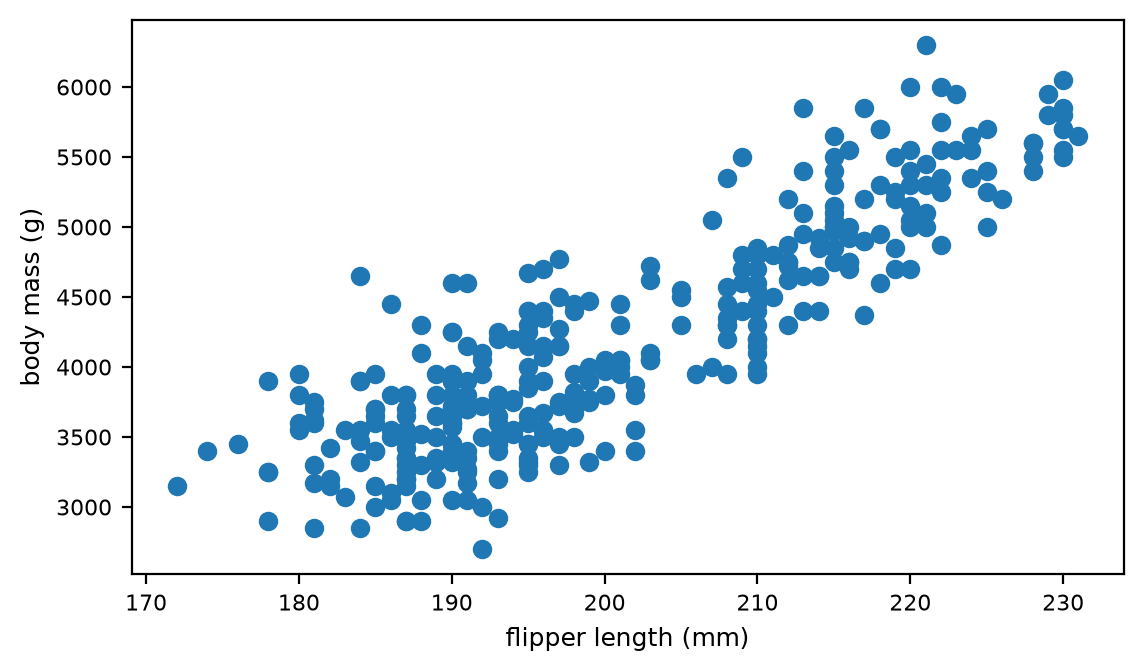

In [846]:
plt.scatter(df_complete["flipper_length_mm"], df_complete["body_mass_g"])
plt.xlabel("flipper length (mm)")
plt.ylabel("body mass (g)");

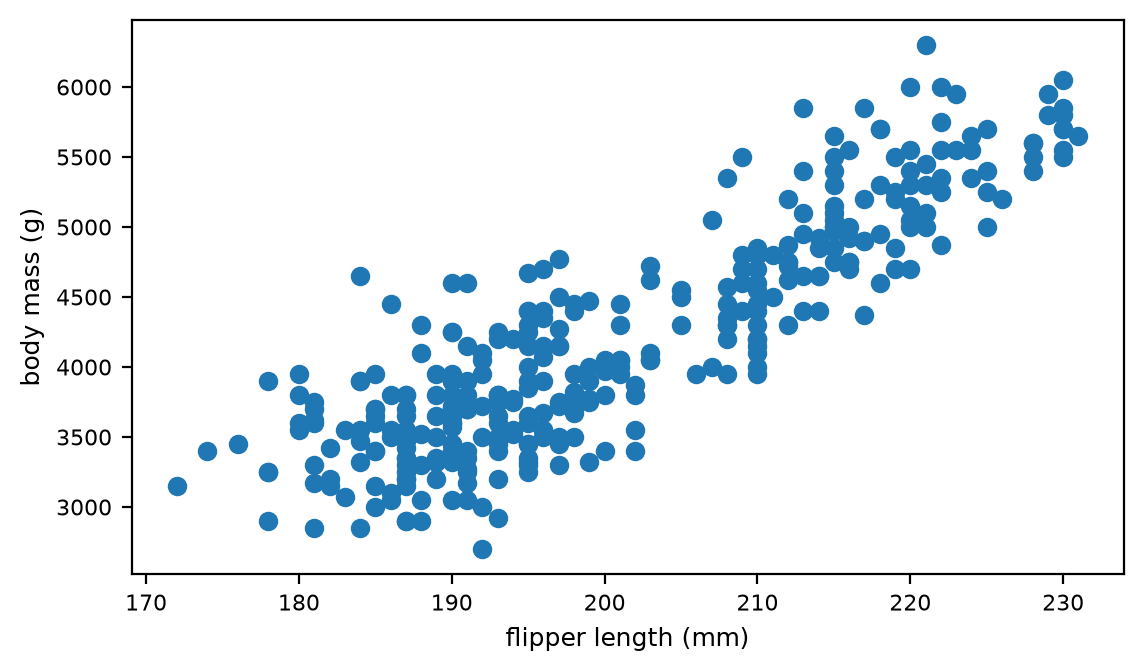

In [847]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.scatter(df_complete["flipper_length_mm"], df_complete["body_mass_g"])
ax.set_xlabel("flipper length (mm)")
ax.set_ylabel("body mass (g)");

*See also:* Plotting a scatter with pandas (B5) · Drawing a scatter plot with `scatterplot` (C3) · Plotting markers only (C1)

#### Colouring points by a value

**C2.02**

`plt.scatter(x, y, c=vals, cmap='viridis'); plt.colorbar()`

The `c=` and `cmap=` arguments allow us to colour each point by a third variable, with `plt.colorbar()` as the key. It is useful for showing a third dimension on a 2-D plot. Alternatively, `hue=` in `sns.scatterplot` colours by category.

In [848]:
# display the example data
df_complete[["flipper_length_mm", "body_mass_g", "bill_length_mm"]].head()

,flipper_length_mm,body_mass_g,bill_length_mm
0,181.0,3750.0,39.1
1,186.0,3800.0,39.5
2,195.0,3250.0,40.3
4,193.0,3450.0,36.7
5,190.0,3650.0,39.3


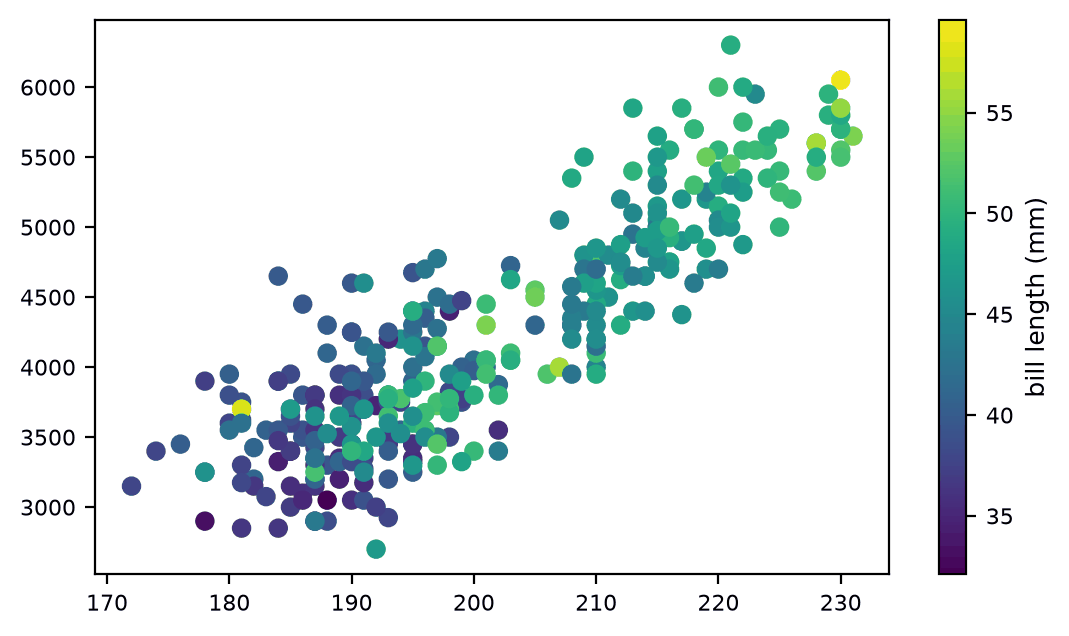

In [849]:
plt.scatter(df_complete["flipper_length_mm"], df_complete["body_mass_g"], c=df_complete["bill_length_mm"], cmap="viridis")
plt.colorbar(label="bill length (mm)");

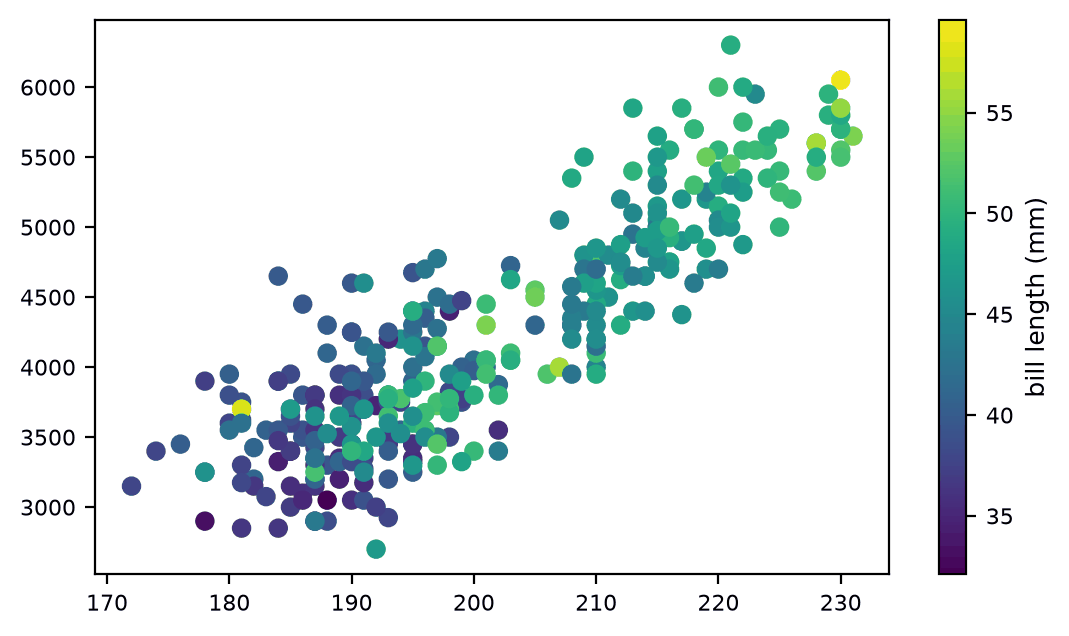

In [850]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
mappable = ax.scatter(df_complete["flipper_length_mm"], df_complete["body_mass_g"], c=df_complete["bill_length_mm"], cmap="viridis")
fig.colorbar(mappable, ax=ax, label="bill length (mm)");

*See also:* Drawing a scatter plot with `scatterplot` (C3) · Drawing a scatter plot (C2) · Colouring points by group (C3) · Sizing points by a value (C2)

#### Sizing points by a value

**C2.03**

`plt.scatter(x, y, s=sizes)`

The `s=` argument allows us to size each point by another variable. It is useful for a "bubble" plot. Alternatively, colour by value or use `size=` in `sns.scatterplot`.

In [851]:
# display the example data
df_complete[["flipper_length_mm", "body_mass_g", "bill_depth_mm"]].head()

,flipper_length_mm,body_mass_g,bill_depth_mm
0,181.0,3750.0,18.7
1,186.0,3800.0,17.4
2,195.0,3250.0,18.0
4,193.0,3450.0,19.3
5,190.0,3650.0,20.6


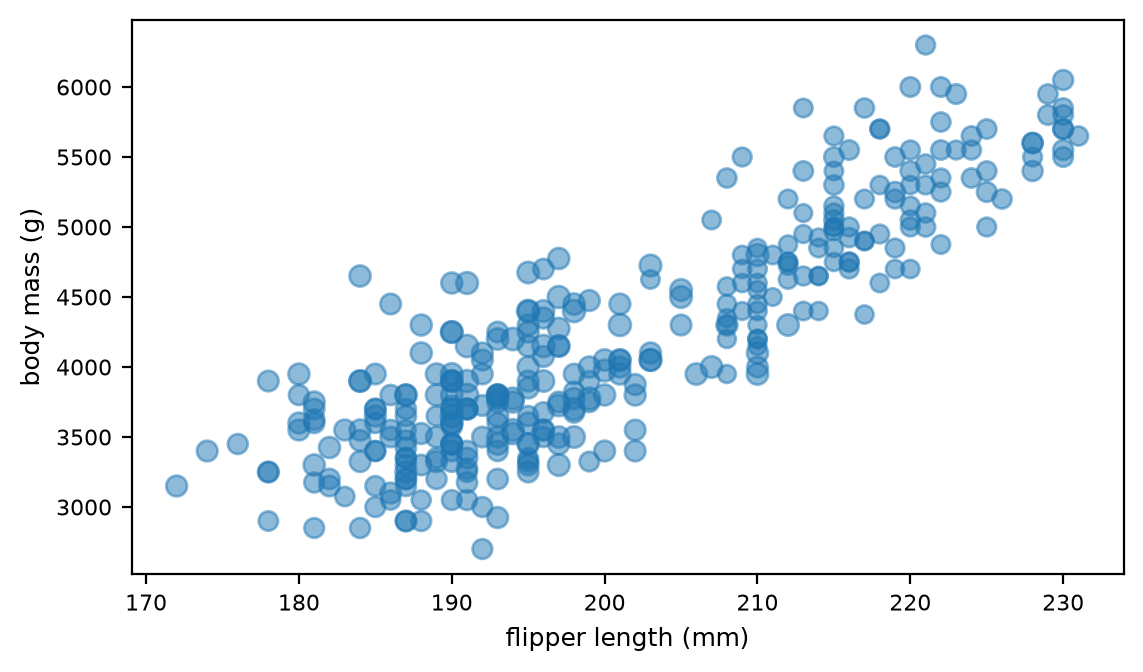

In [852]:
plt.scatter(df_complete["flipper_length_mm"], df_complete["body_mass_g"], s=df_complete["bill_depth_mm"] * 3, alpha=0.5)
plt.xlabel("flipper length (mm)")
plt.ylabel("body mass (g)");

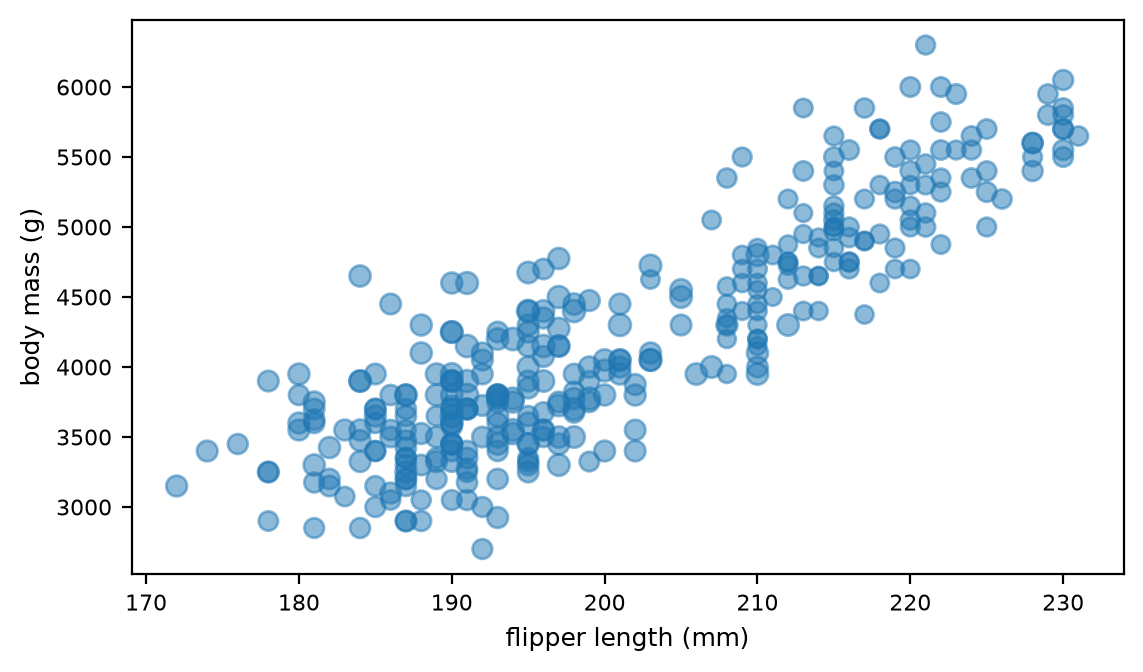

In [853]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.scatter(df_complete["flipper_length_mm"], df_complete["body_mass_g"], s=df_complete["bill_depth_mm"] * 3, alpha=0.5)
ax.set_xlabel("flipper length (mm)")
ax.set_ylabel("body mass (g)");

Larger points have a greater bill depth. `alpha=0.5` makes overlapping points visible.

*See also:* Drawing a scatter plot with `scatterplot` (C3) · Drawing a scatter plot (C2)

### Bar charts

#### Drawing a bar chart

**C2.04**

`plt.bar(x, h, color=c, width=w)`

The `plt.bar(x, height)` function allows us to draw one bar per category. It is useful for counts or other values per group. Alternatively, `sns.barplot`, `sns.countplot` or `Series.plot.bar()` draw from the data.

In [854]:
col_counts = df_complete["species"].value_counts()
col_counts

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

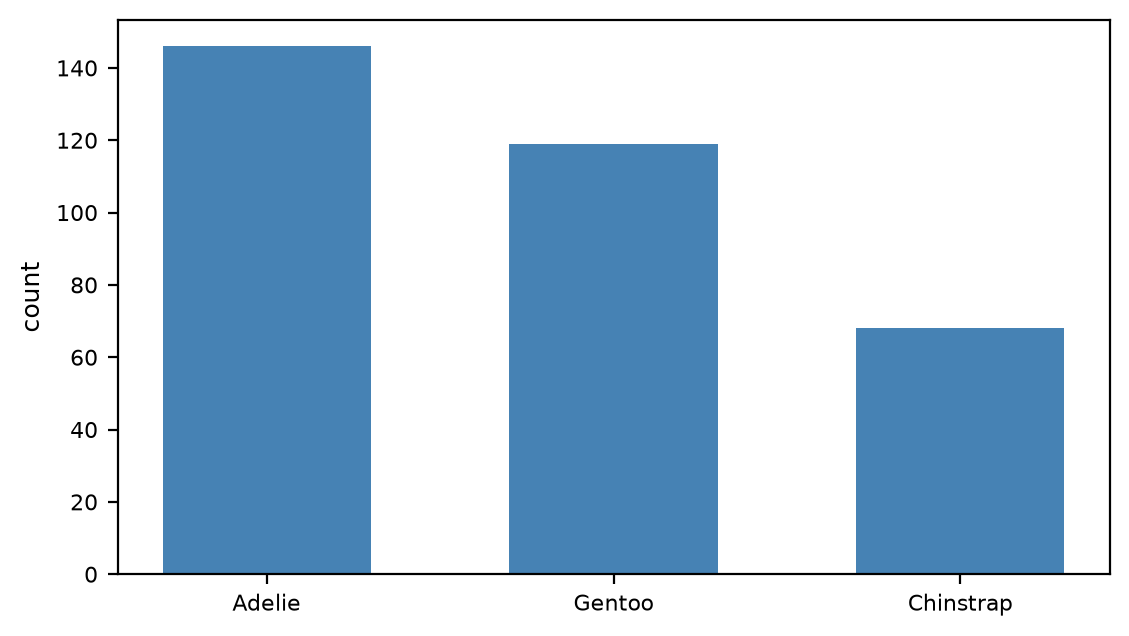

In [855]:
plt.bar(col_counts.index, col_counts.values, color="steelblue", width=0.6)
plt.ylabel("count");

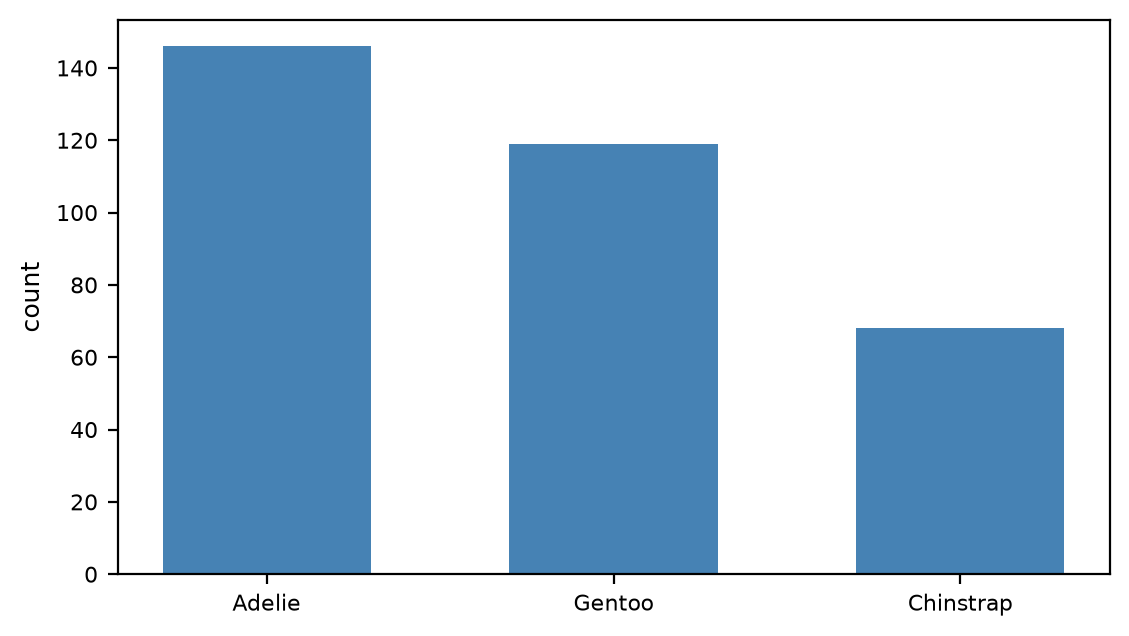

In [856]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.bar(col_counts.index, col_counts.values, color="steelblue", width=0.6)
ax.set_ylabel("count");

*See also:* Counting categories with `countplot` (C3) · Drawing horizontal bars (C2) · Counting each category (B5) · Drawing a bar plot of values (C3) · Starting bar charts at zero (C4)

#### Drawing horizontal bars

**C2.05**

`plt.barh(y, w)`

The `plt.barh()` function allows us to draw bars sideways. It is useful when category names are long. Alternatively, swap the axes in seaborn with `y=` for the category.

In [857]:
# display the example data
col_counts = df_complete["species"].value_counts()
col_counts

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

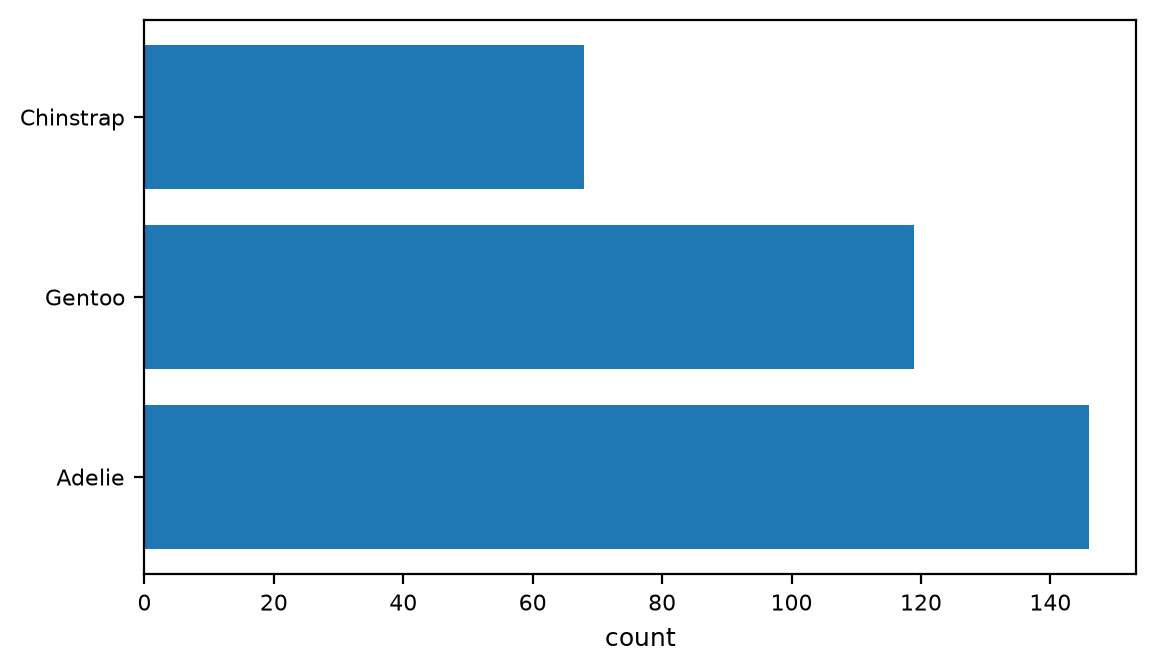

In [858]:
plt.barh(col_counts.index, col_counts.values)
plt.xlabel("count");

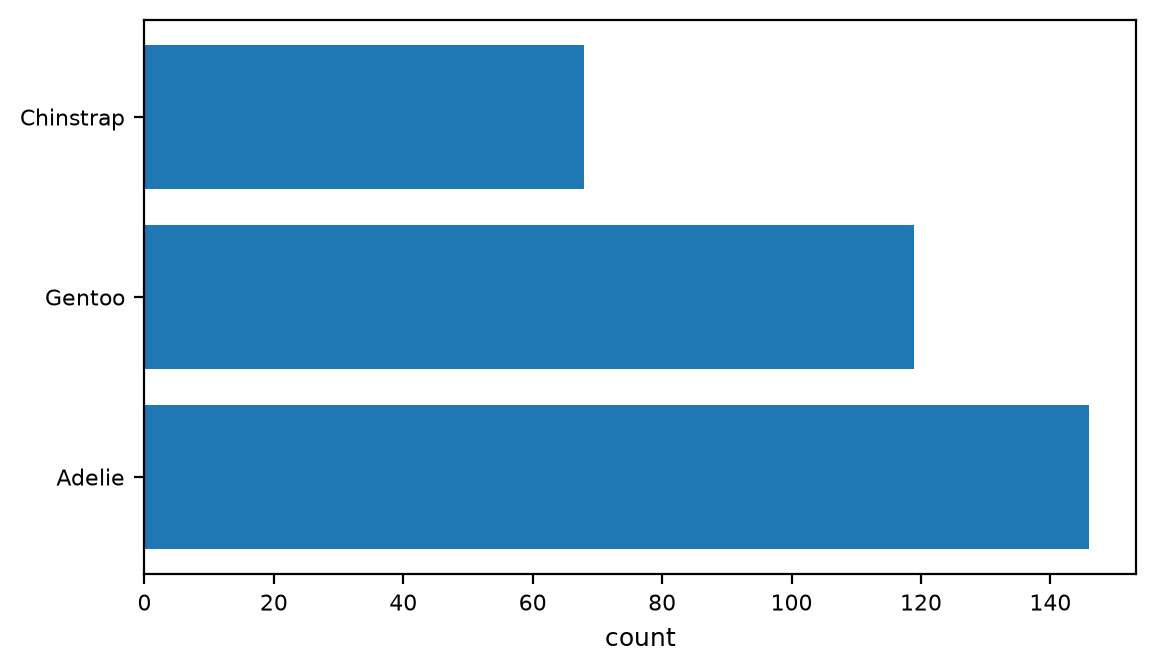

In [859]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.barh(col_counts.index, col_counts.values)
ax.set_xlabel("count");

*See also:* Drawing a bar chart (C2) · Drawing a probability bar plot (C2)

#### Drawing a probability bar plot

**C2.06**

`plt.bar(events, P_events, width=0.6)`

If we have a list of outcomes and their probabilities, then a bar plot shows the shape of the probability distribution. It is useful for discrete outcomes with known probabilities. Alternatively, `sns.barplot` on a table with a probability column does the same.

In [860]:
faces = [1, 2, 3, 4, 5, 6]
prob = [1 / 6] * 6
print(f"sum of probabilities = {sum(prob):.2f}")

sum of probabilities = 1.00


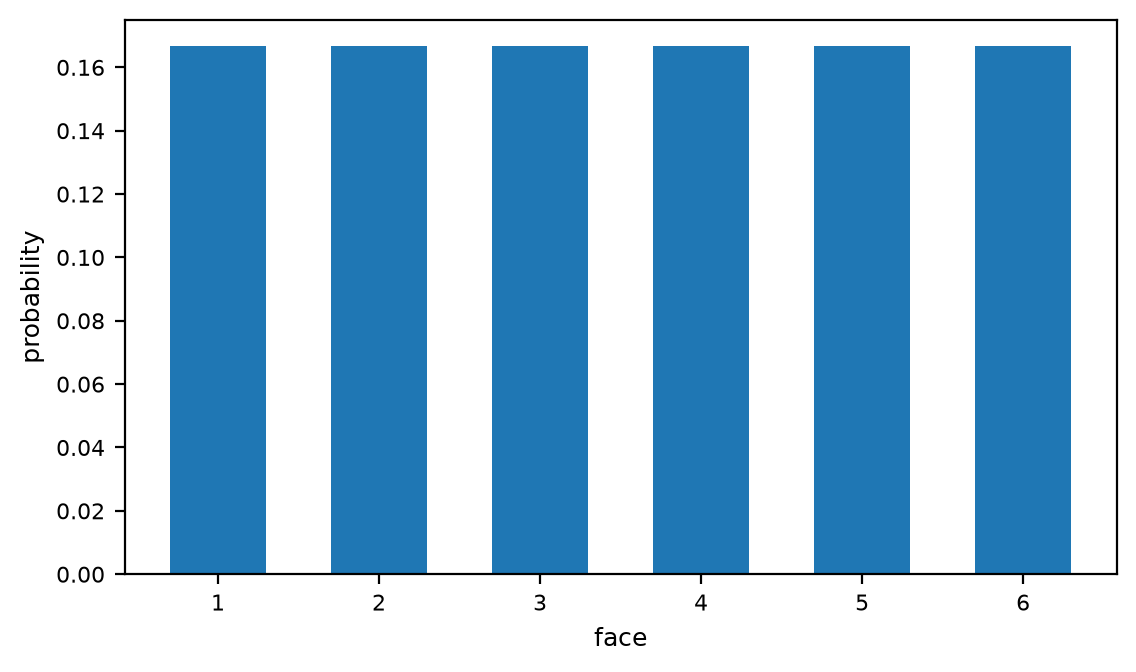

In [861]:
plt.bar(faces, prob, width=0.6)
plt.xlabel("face")
plt.ylabel("probability");

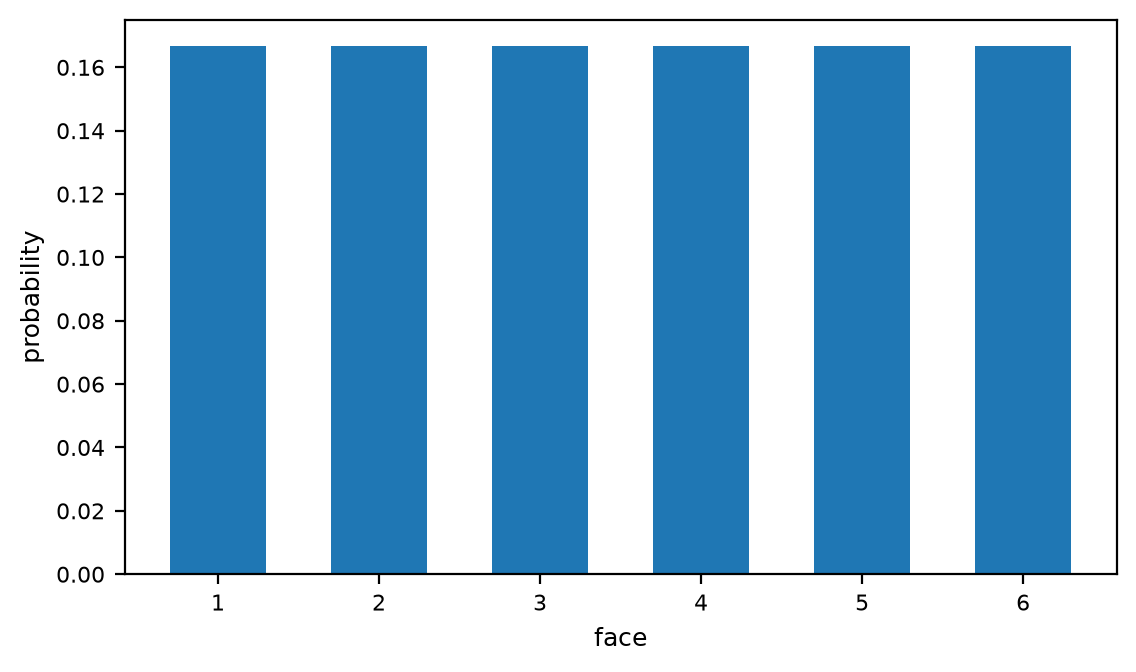

In [862]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.bar(faces, prob, width=0.6)
ax.set_xlabel("face")
ax.set_ylabel("probability");

*See also:* Drawing a bar plot of values (C3) · Plotting a probability distribution (D1) · Turning counts into probabilities (B4) · Drawing a bar chart (C2)

### Histograms

#### Drawing a histogram

**C2.07**

`plt.hist(data, bins=n)`

The `plt.hist()` function allows us to show how values are distributed by counting them in bins. It is useful for checking the shape, centre and spread of a variable. Alternatively, `sns.histplot` or `Series.plot.hist()` do the same.

In [863]:
# display the example data
df_complete["body_mass_g"].describe().round(0)

count     333.0
mean     4207.0
std       805.0
min      2700.0
25%      3550.0
50%      4050.0
75%      4775.0
max      6300.0
Name: body_mass_g, dtype: float64

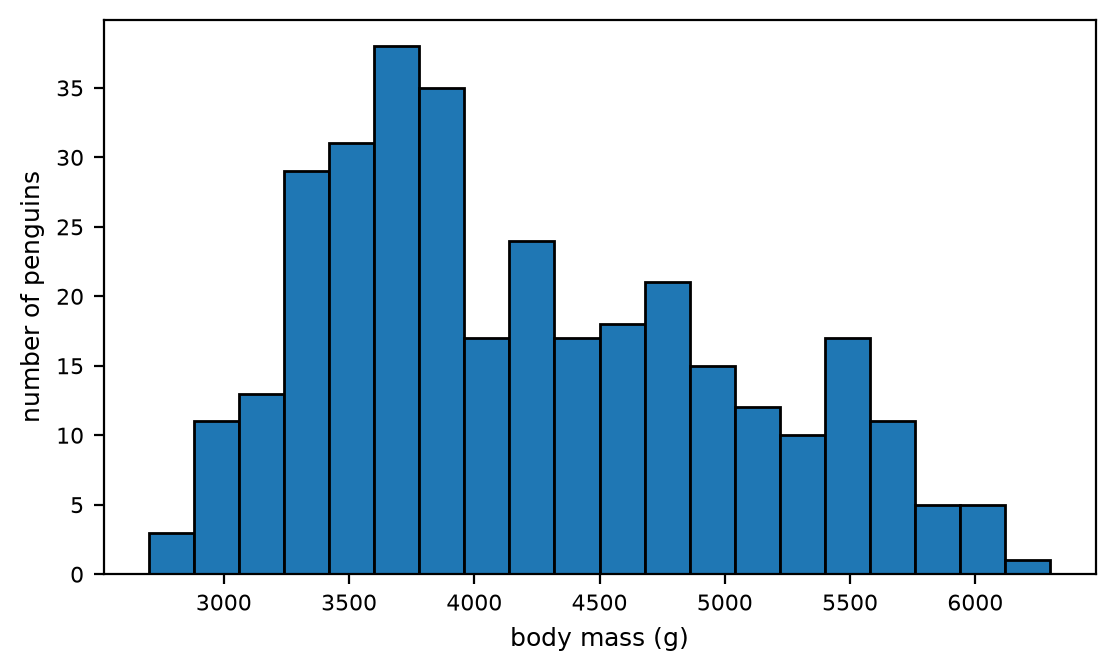

In [864]:
plt.hist(df_complete["body_mass_g"], bins=20, edgecolor="black")
plt.xlabel("body mass (g)")
plt.ylabel("number of penguins");

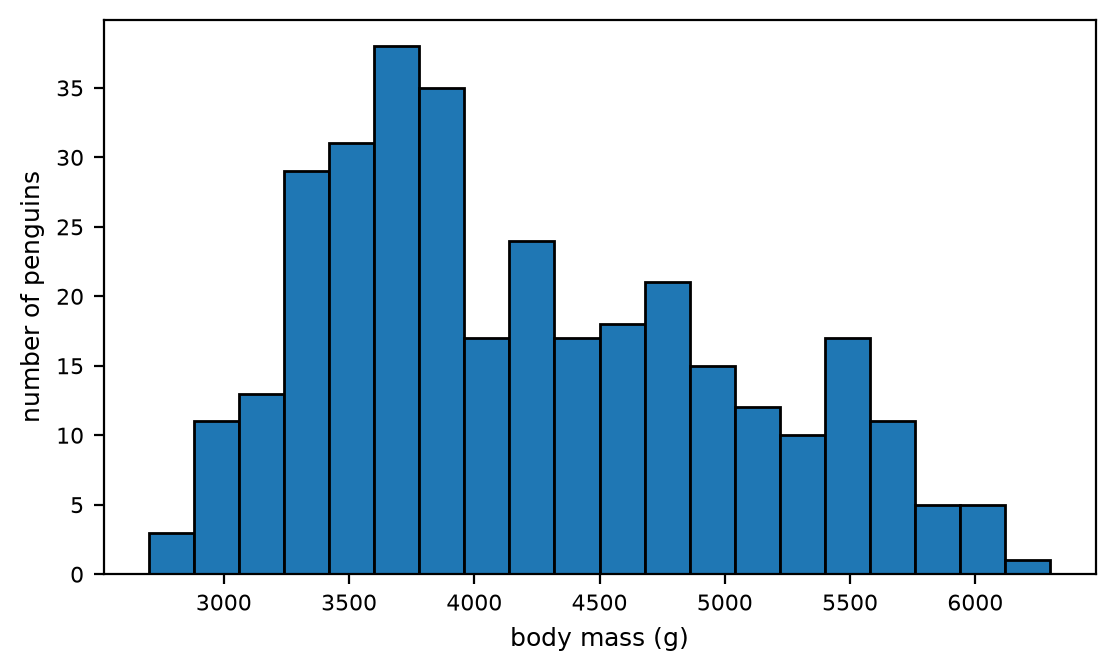

In [865]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.hist(df_complete["body_mass_g"], bins=20, edgecolor="black")
ax.set_xlabel("body mass (g)")
ax.set_ylabel("number of penguins");

More bins show more detail but are noisier:

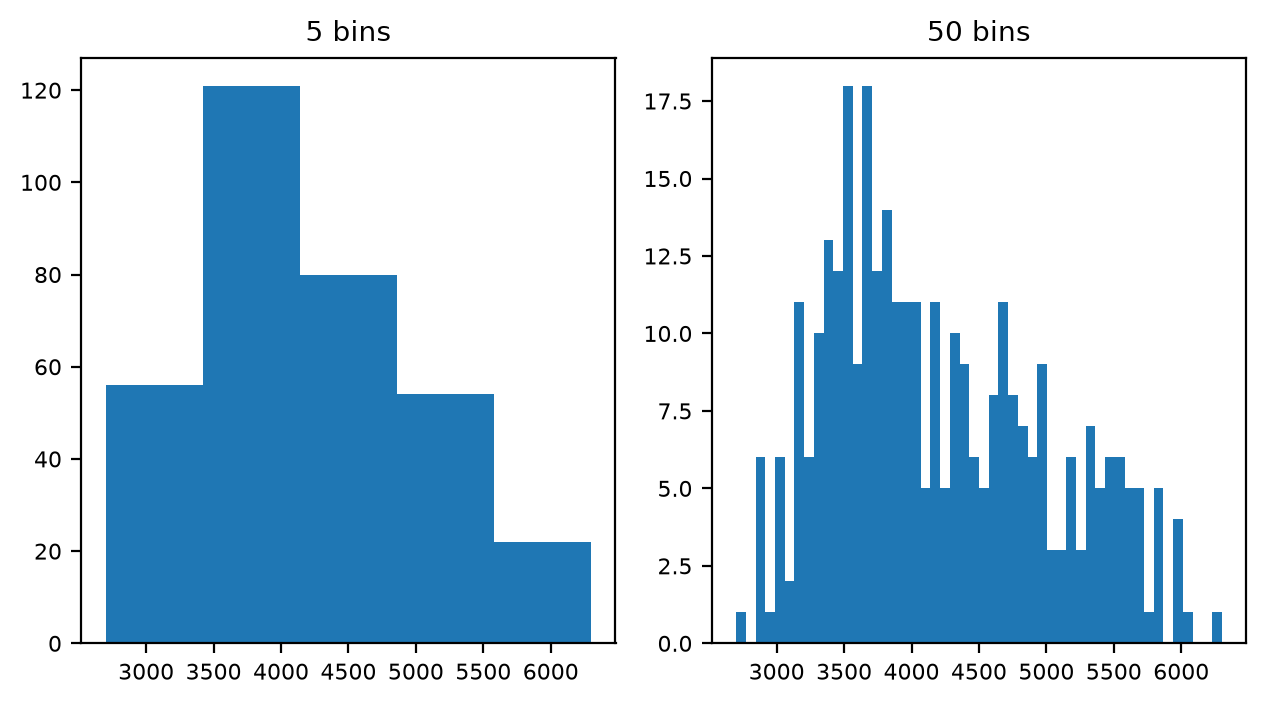

In [866]:
plt.subplot(1, 2, 1); plt.hist(df_complete["body_mass_g"], bins=5);  plt.title("5 bins")
plt.subplot(1, 2, 2); plt.hist(df_complete["body_mass_g"], bins=50); plt.title("50 bins")
plt.tight_layout();

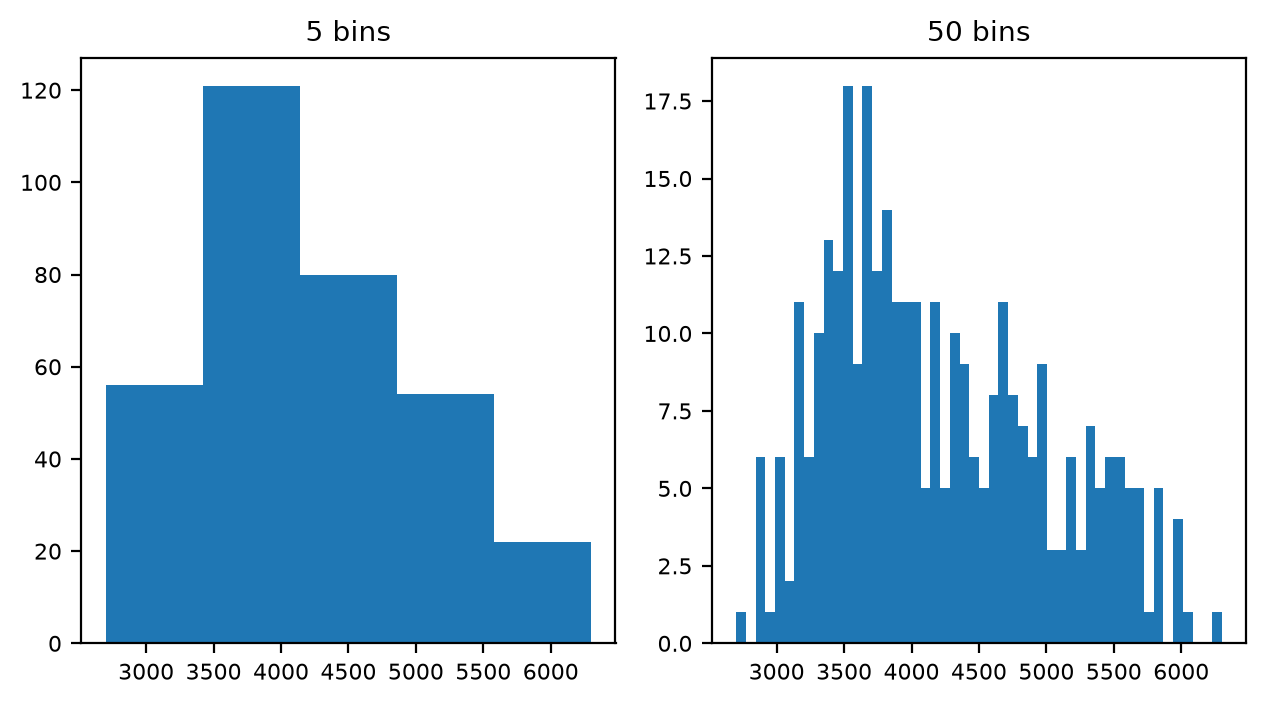

In [867]:
# the same plot in object-oriented style (ax. methods)
fig, axs = plt.subplots(1, 2)
ax = axs[0]; ax.hist(df_complete["body_mass_g"], bins=5);  ax.set_title("5 bins")
ax = axs[1]; ax.hist(df_complete["body_mass_g"], bins=50); ax.set_title("50 bins")
fig.tight_layout();

*See also:* Choosing bin edges (C2) · Drawing a histogram with `histplot` (C3) · Plotting a histogram with pandas (B5)

#### Choosing bin edges

**C2.08**

`bins=np.arange(start, stop, step), bins=np.linspace(start, stop, n)`

Passing an array of edges to `bins=` allows us to choose exactly where bins start and end. It is useful for round numbers or when comparing histograms. Alternatively, `bins=n` lets matplotlib choose the edges.

[2500 3000 3500 4000 4500 5000 5500 6000 6500]


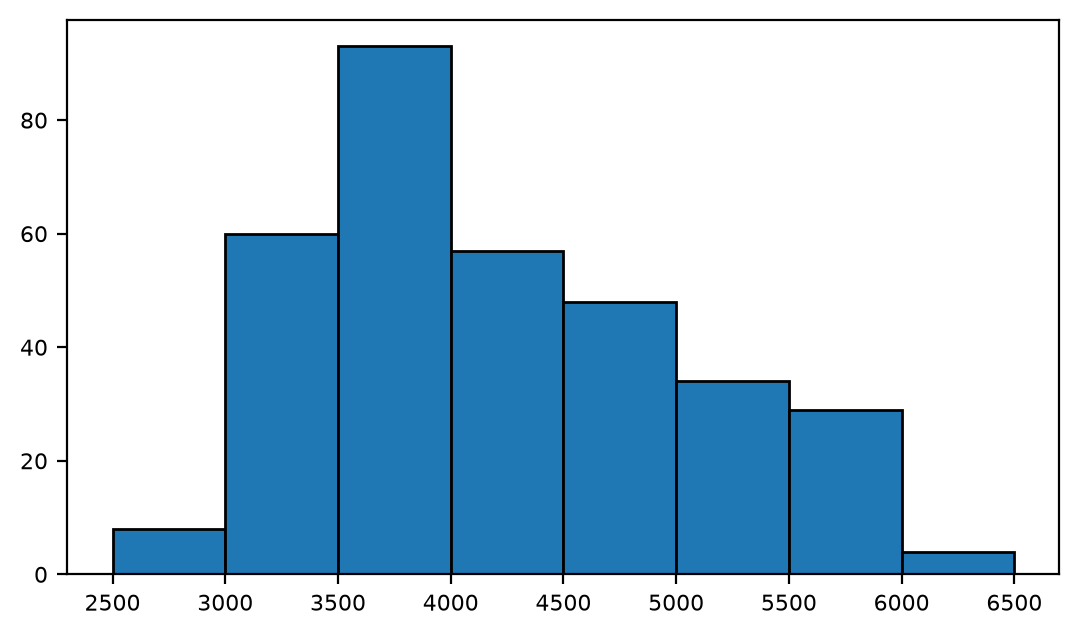

In [868]:
edges = np.arange(2500, 6600, 500)
print(edges)
plt.hist(df_complete["body_mass_g"], bins=edges, edgecolor="black");

[2500 3000 3500 4000 4500 5000 5500 6000 6500]


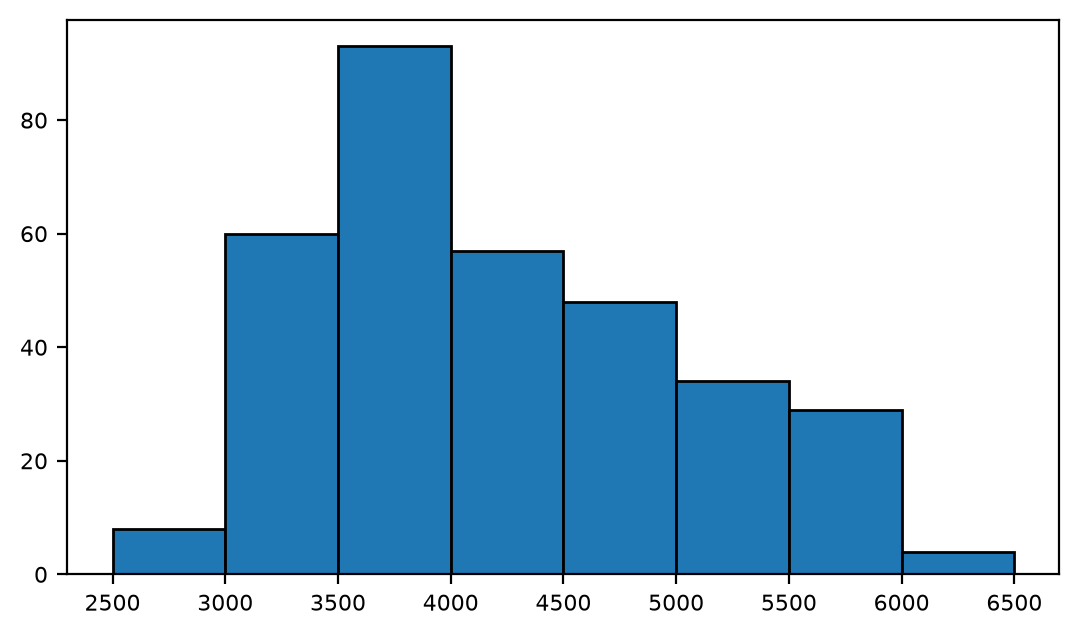

In [869]:
# the same plot in object-oriented style (ax. methods)
edges = np.arange(2500, 6600, 500)
print(edges)
fig, ax = plt.subplots()
ax.hist(df_complete["body_mass_g"], bins=edges, edgecolor="black");

*See also:* Drawing a histogram (C2) · Creating a sequence with `np.arange` (A4) · Creating evenly spaced points with `np.linspace` (A4) · Normalising a histogram (C3)

#### Scaling a histogram as a density

**C2.09**

`plt.hist(data, density=True)`

***(non-examinable)***

The `density=True` option allows us to scale a histogram so its total area is 1. It is useful for comparing with a probability density curve. Alternatively, `sns.histplot(stat="density")` does the same.

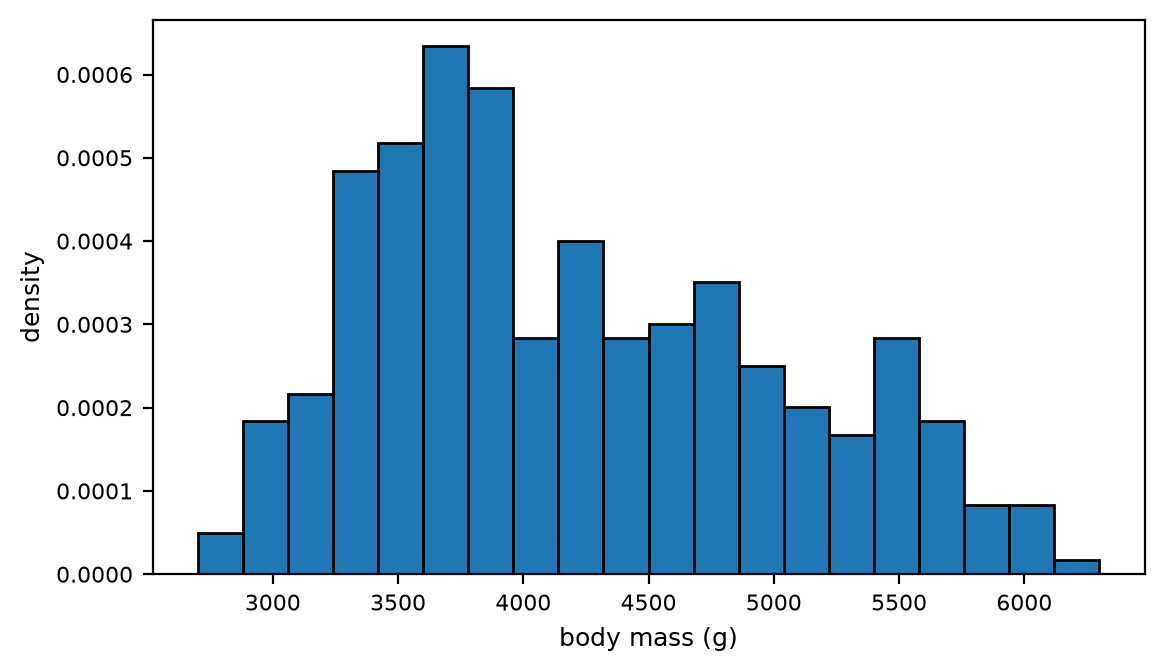

In [870]:
plt.hist(df_complete["body_mass_g"], bins=20, density=True, edgecolor="black")
plt.xlabel("body mass (g)")
plt.ylabel("density");

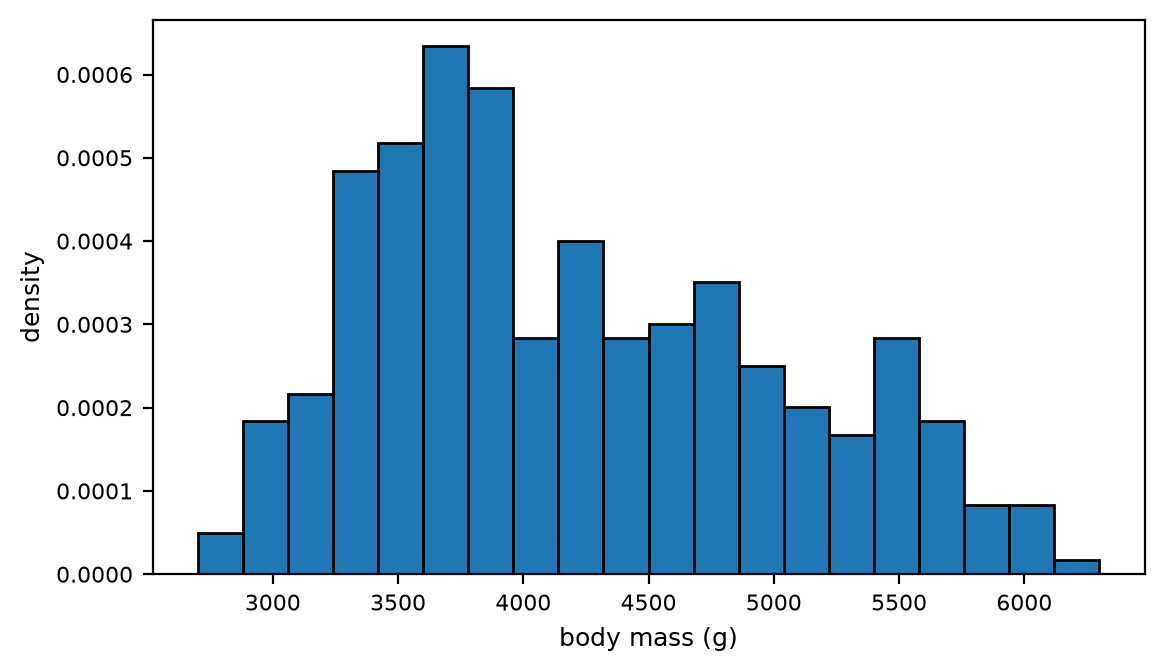

In [871]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.hist(df_complete["body_mass_g"], bins=20, density=True, edgecolor="black")
ax.set_xlabel("body mass (g)")
ax.set_ylabel("density");

*See also:* Drawing a histogram with `histplot` (C3) · Comparing a histogram with a normal curve (D2) · Normalising a histogram (C3) · Choosing bin edges (C2)

### Box plots and pie charts

#### Drawing a box plot

**C2.10**

`plt.boxplot(data)`

The `plt.boxplot()` function allows us to summarise a variable's median, quartiles and outliers in one picture. It is useful for spotting skew and outliers. Alternatively, `sns.boxplot` adds grouping and colour.

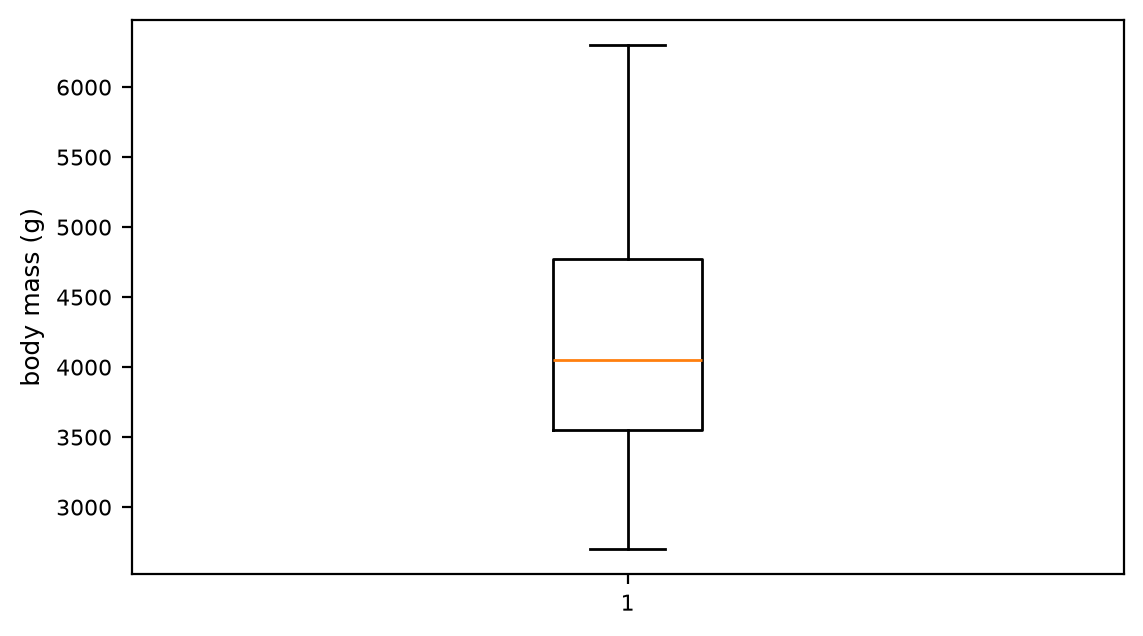

In [872]:
plt.boxplot(df_complete["body_mass_g"])
plt.ylabel("body mass (g)");

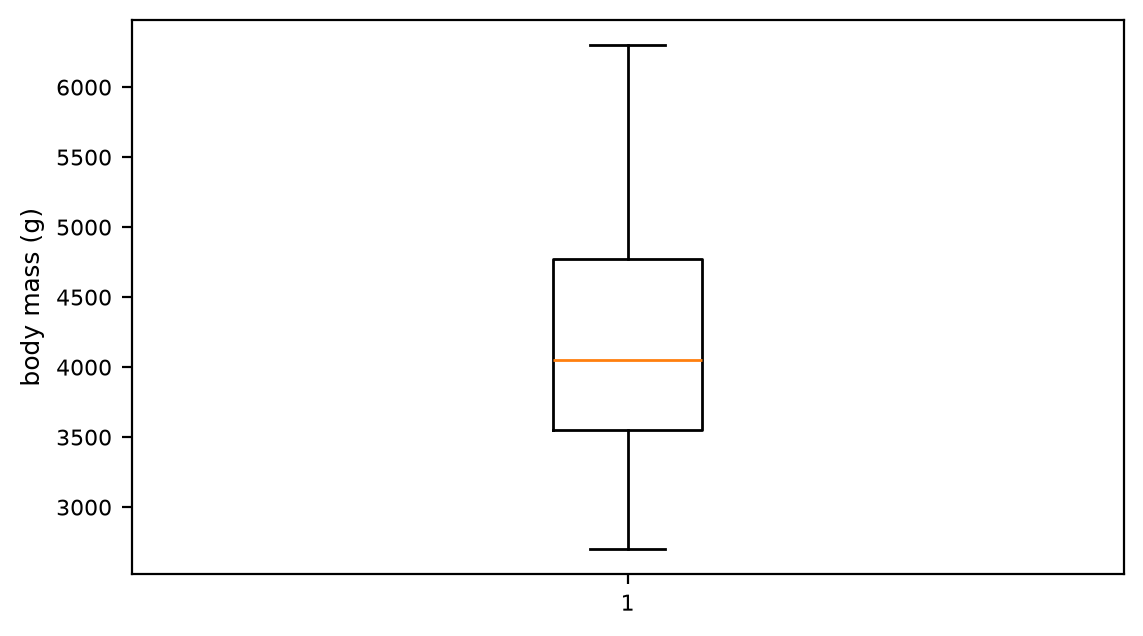

In [873]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.boxplot(df_complete["body_mass_g"])
ax.set_ylabel("body mass (g)");

*See also:* Drawing a box plot with `boxplot` (C3) · Drawing several box plots (C2) · Finding quartiles (B5)

#### Drawing several box plots

**C2.11**

`plt.boxplot([s1, s2], tick_labels=names)`

Passing a list of arrays to `plt.boxplot()` allows us to compare groups side by side. It is useful for judging whether groups differ in centre or spread. Alternatively, `sns.boxplot(data=df, x=, y=)` does the splitting automatically.

Adelie, Chinstrap and Gentoo are the three penguin species in this dataset.
`tick_labels=` needs matplotlib 3.9 or later (older versions call it `labels=`).

In [874]:
species = ["Adelie", "Chinstrap", "Gentoo"]
groups = [df_complete.loc[df_complete["species"] == s, "body_mass_g"] for s in species]
print(f"{[len(g) for g in groups]} penguins in each group")

[146, 68, 119] penguins in each group


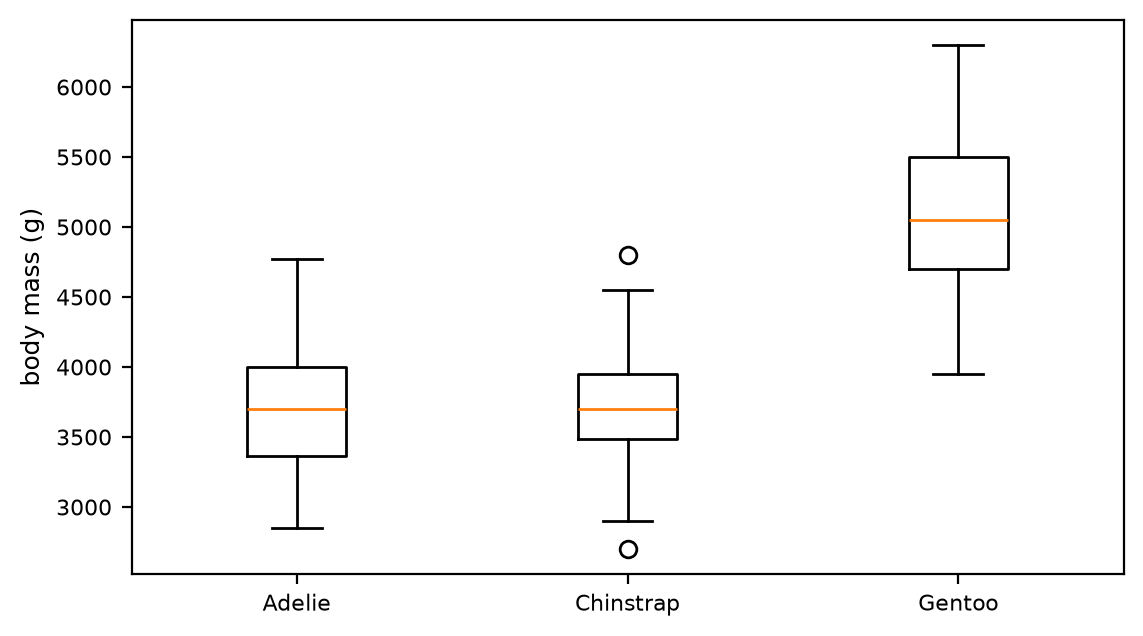

In [875]:
plt.boxplot(groups, tick_labels=species)
plt.ylabel("body mass (g)");

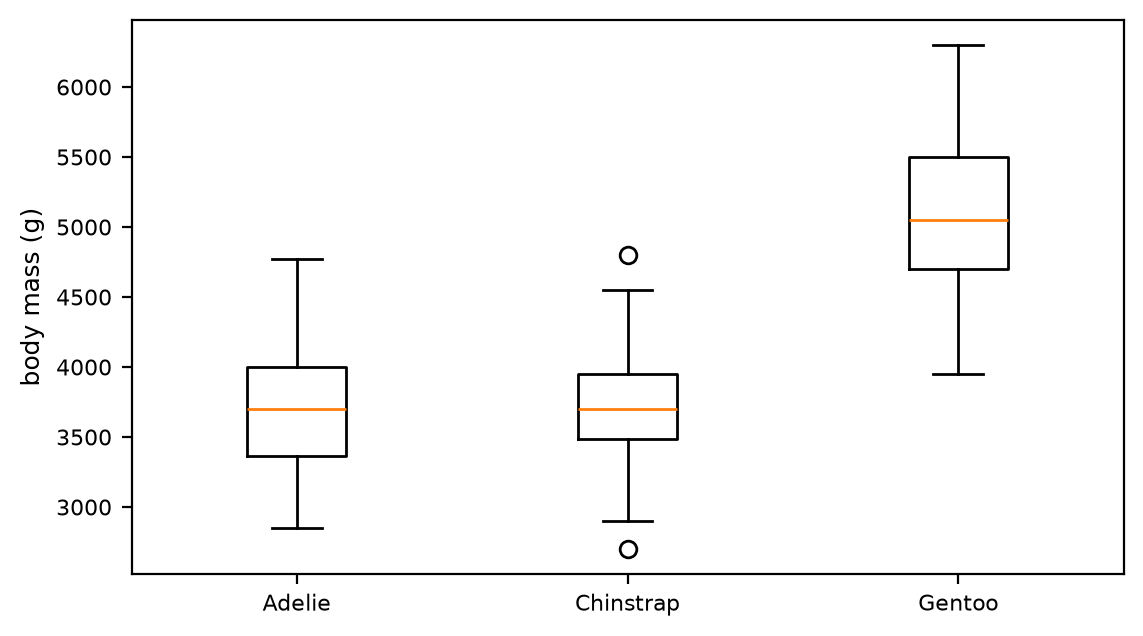

In [876]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.boxplot(groups, tick_labels=species)
ax.set_ylabel("body mass (g)");

*See also:* Drawing a box plot with `boxplot` (C3) · Drawing a box plot (C2)

#### Drawing a pie chart

**C2.12**

`plt.pie(sizes, labels=names, explode=offsets, autopct='%1.1f%%', startangle=angle)`

The `plt.pie()` function allows us to show how a whole is divided into parts. It is useful for a few categories with clear shares. Alternatively, a bar chart is usually read more accurately.

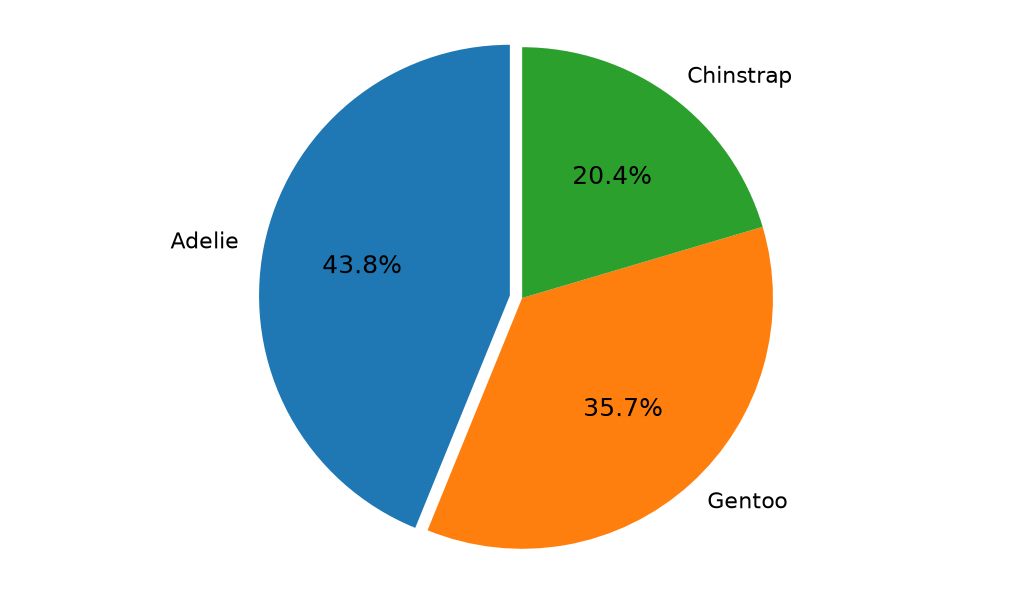

In [877]:
col_counts = df_complete["species"].value_counts()
plt.pie(col_counts.values, labels=col_counts.index, explode=[0.05, 0, 0],
        autopct="%1.1f%%", startangle=90)
plt.axis("equal");

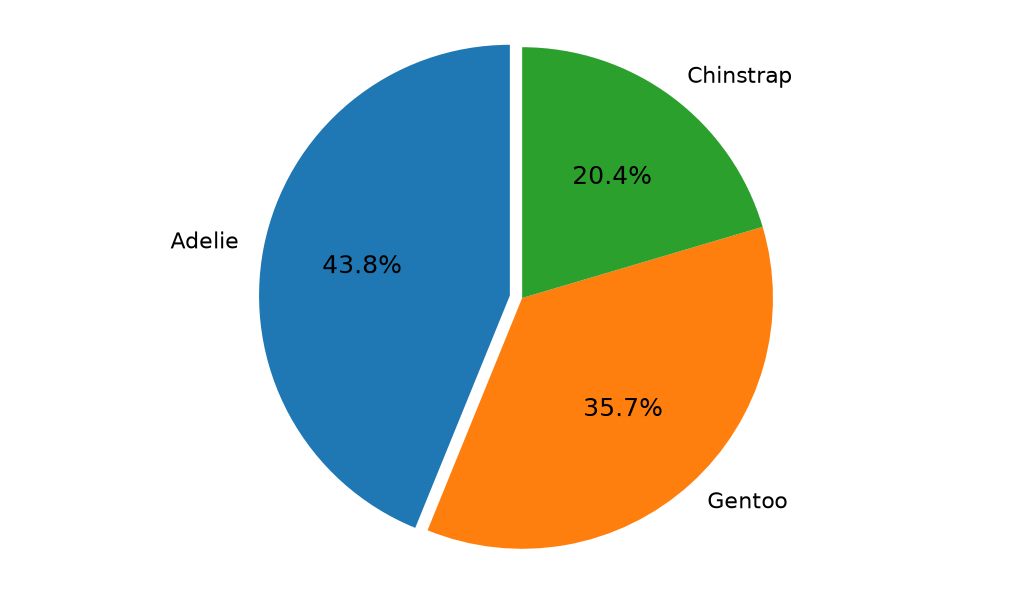

In [878]:
# the same plot in object-oriented style (ax. methods)
col_counts = df_complete["species"].value_counts()
fig, ax = plt.subplots()
ax.pie(col_counts.values, labels=col_counts.index, explode=[0.05, 0, 0],
        autopct="%1.1f%%", startangle=90)
ax.axis("equal");

*See also:* Drawing a bar chart (C2) · Counting each category (B5)

### Panels

#### Drawing panels with `plt.subplot`

**C2.13**

`plt.subplot(rows, cols, i)`

The `plt.subplot(rows, cols, i)` function allows us to put several plots in a grid, choosing the panel number each time. It is useful for side-by-side comparison. Alternatively, `plt.subplots()` creates all the panels at once.

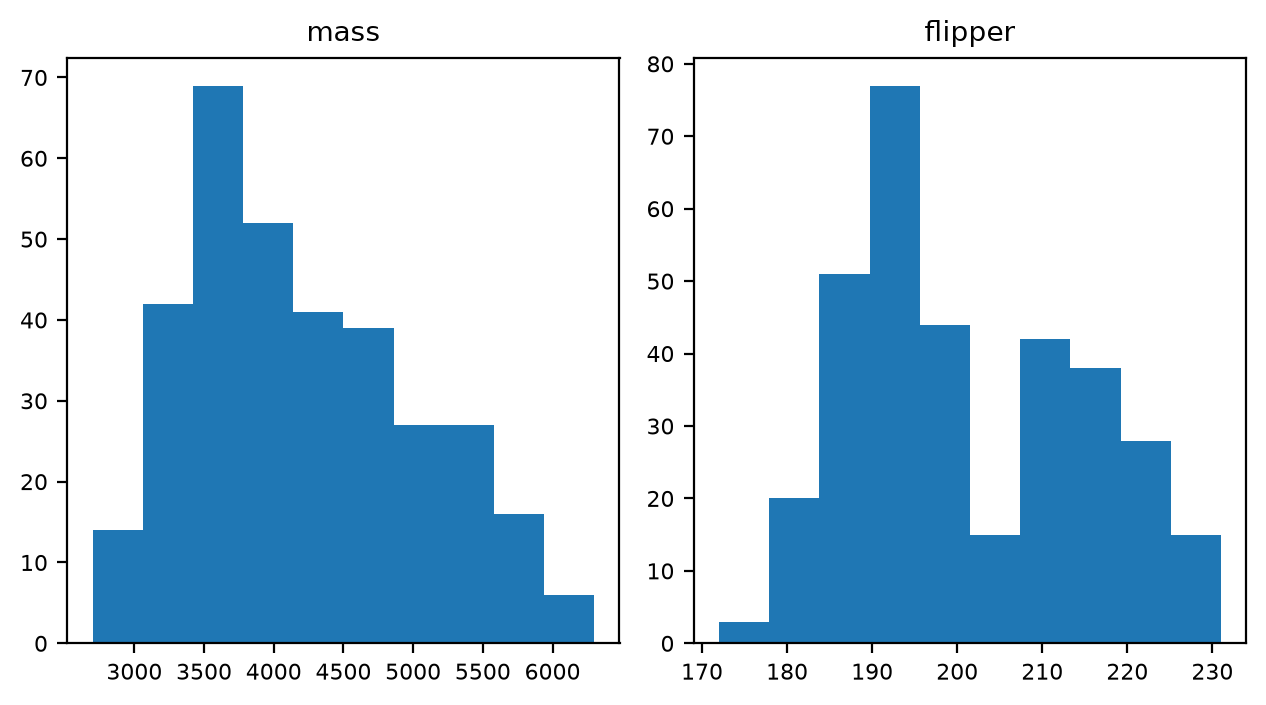

In [879]:
plt.subplot(1, 2, 1)            # 1 row, 2 columns, panel 1
plt.hist(df_complete["body_mass_g"])
plt.title("mass")
plt.subplot(1, 2, 2)            # panel 2
plt.hist(df_complete["flipper_length_mm"])
plt.title("flipper")
plt.tight_layout();

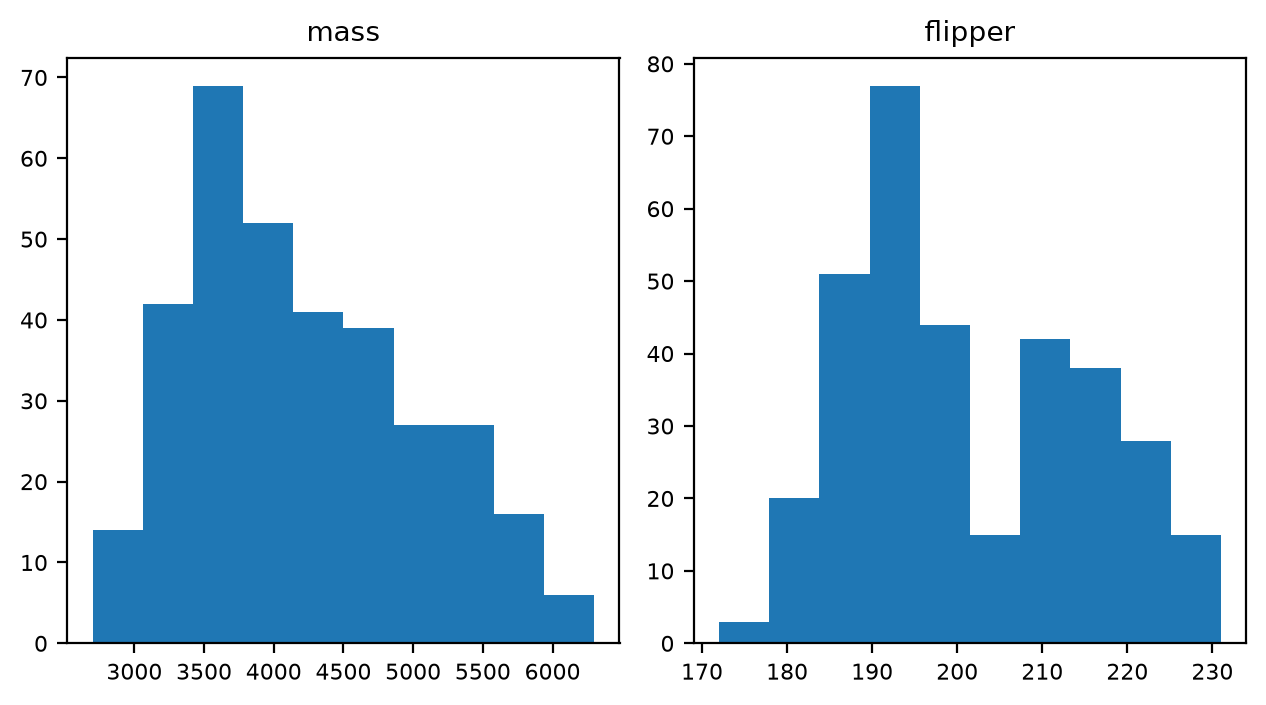

In [880]:
# the same plot in object-oriented style (ax. methods)
fig, axs = plt.subplots(1, 2)
ax = axs[0]            # 1 row, 2 columns, panel 1
ax.hist(df_complete["body_mass_g"])
ax.set_title("mass")
ax = axs[1]            # panel 2
ax.hist(df_complete["flipper_length_mm"])
ax.set_title("flipper")
fig.tight_layout();

*See also:* Adding an overall title and tight layout (C2) · Drawing panels with `plt.subplots` (C2) · Choosing between `plt` and `ax` (C1)

#### Adding an overall title and tight layout

**C2.14**

`plt.suptitle(), plt.tight_layout()`

The `plt.suptitle()` and `plt.tight_layout()` functions allow us to add a title above all panels and stop panels overlapping. They are useful for any multi-panel figure. Alternatively, `fig.suptitle()` and `constrained_layout=True` do the same.

Without `tight_layout`, labels of neighbouring panels can overlap:

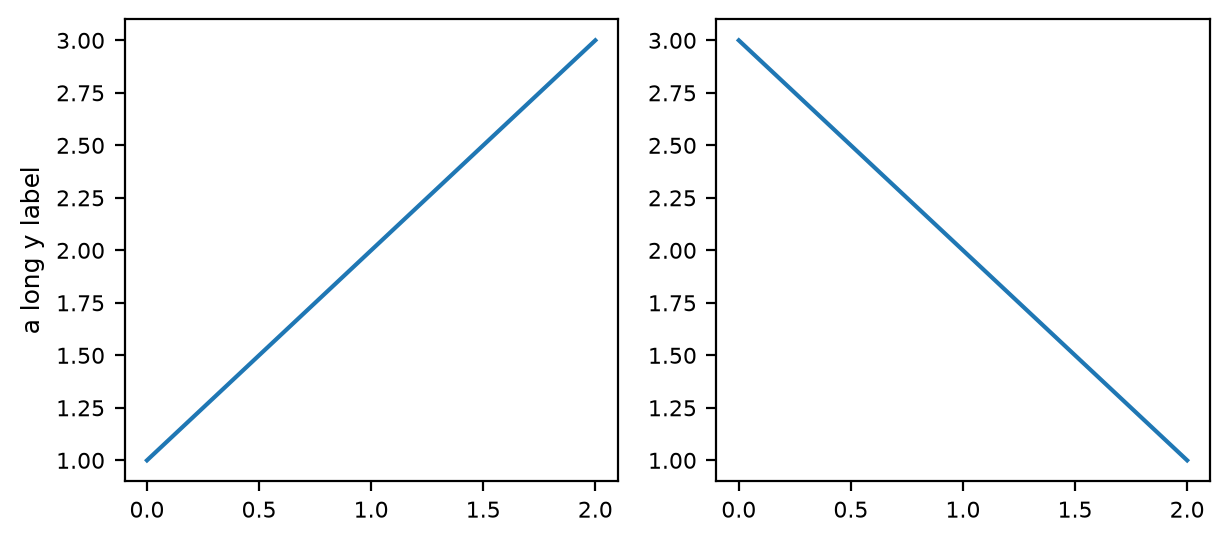

In [881]:
plt.figure(figsize=(7, 3))
plt.subplot(1, 2, 1); plt.plot([1, 2, 3]); plt.ylabel("a long y label")
plt.subplot(1, 2, 2); plt.plot([3, 2, 1]);

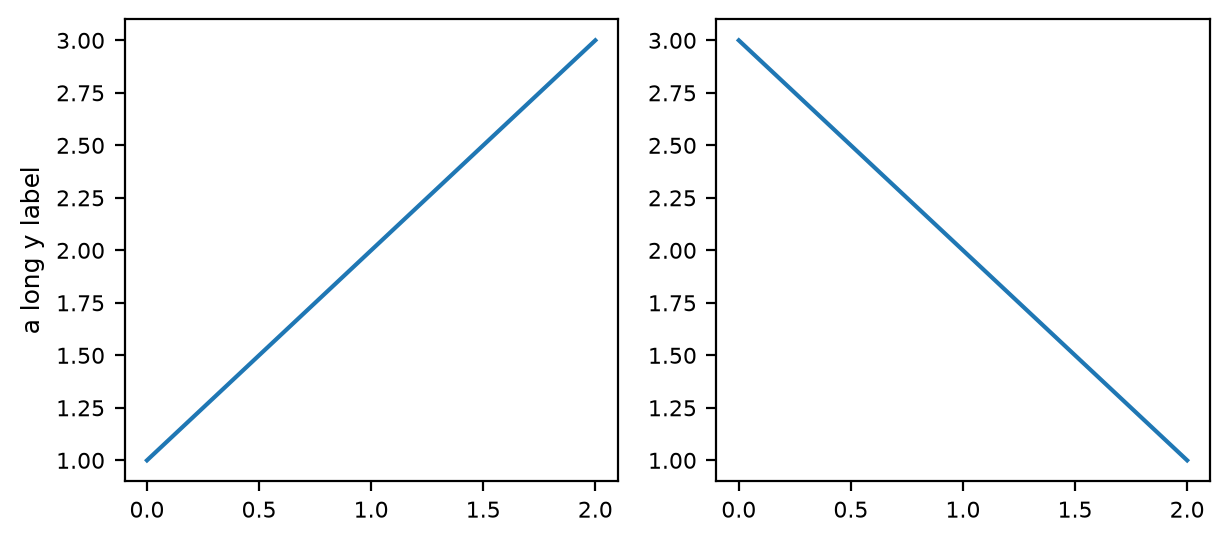

In [882]:
# the same plot in object-oriented style (ax. methods)
fig, axs = plt.subplots(1, 2, figsize=(7, 3))
ax = axs[0]; ax.plot([1, 2, 3]); ax.set_ylabel("a long y label")
ax = axs[1]; ax.plot([3, 2, 1]);

`suptitle` adds a title above all panels and `tight_layout` adjusts the spacing:

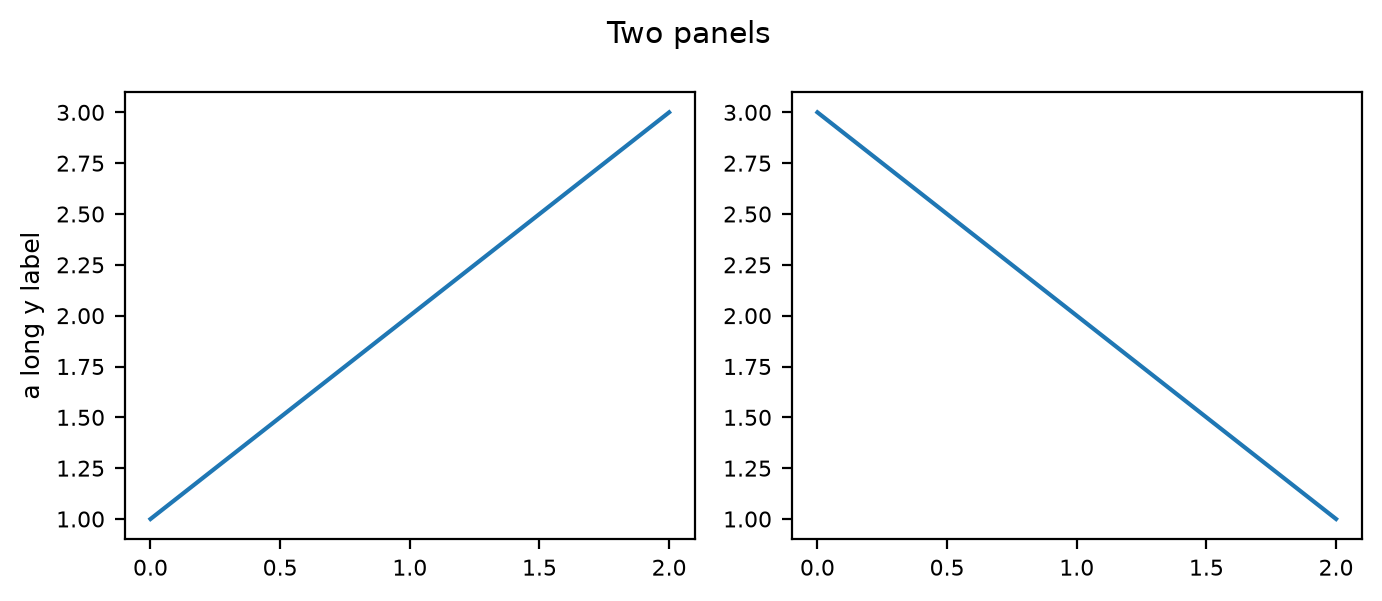

In [883]:
plt.figure(figsize=(7, 3))
plt.subplot(1, 2, 1); plt.plot([1, 2, 3]); plt.ylabel("a long y label")
plt.subplot(1, 2, 2); plt.plot([3, 2, 1])
plt.suptitle("Two panels")
plt.tight_layout();

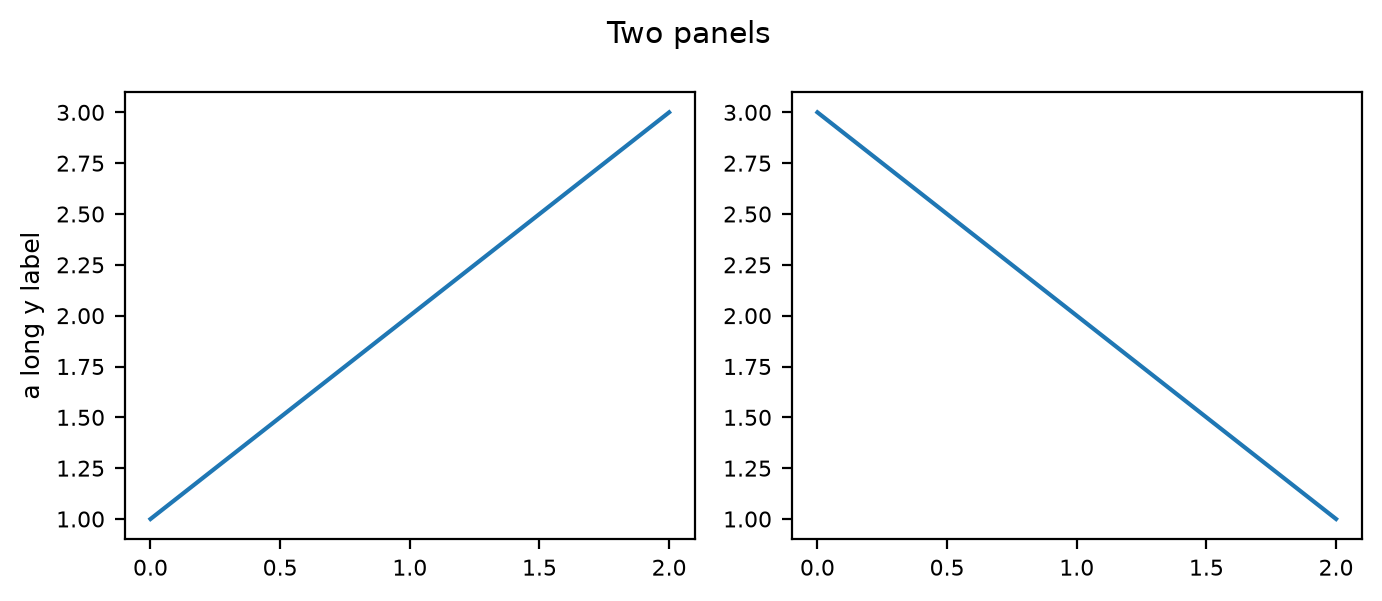

In [884]:
# the same plot in object-oriented style (ax. methods)
fig, axs = plt.subplots(1, 2, figsize=(7, 3))
ax = axs[0]; ax.plot([1, 2, 3]); ax.set_ylabel("a long y label")
ax = axs[1]; ax.plot([3, 2, 1])
fig.suptitle("Two panels")
fig.tight_layout();

*See also:* Drawing panels with `plt.subplot` (C2) · Drawing panels with `plt.subplots` (C2) · Setting figure size and resolution (C1)

#### Drawing panels with `plt.subplots`

**C2.15**

`fig, axs = plt.subplots(rows, cols); axs[0].set(title=text)`

The `fig, axs = plt.subplots()` pattern allows us to create the figure and all its axes together, then draw on each axis by name. It is useful for more complex figures and because `ax.set(...)` can set several labels at once. Alternatively, `plt.subplot` with `plt.*` commands works for simple cases.

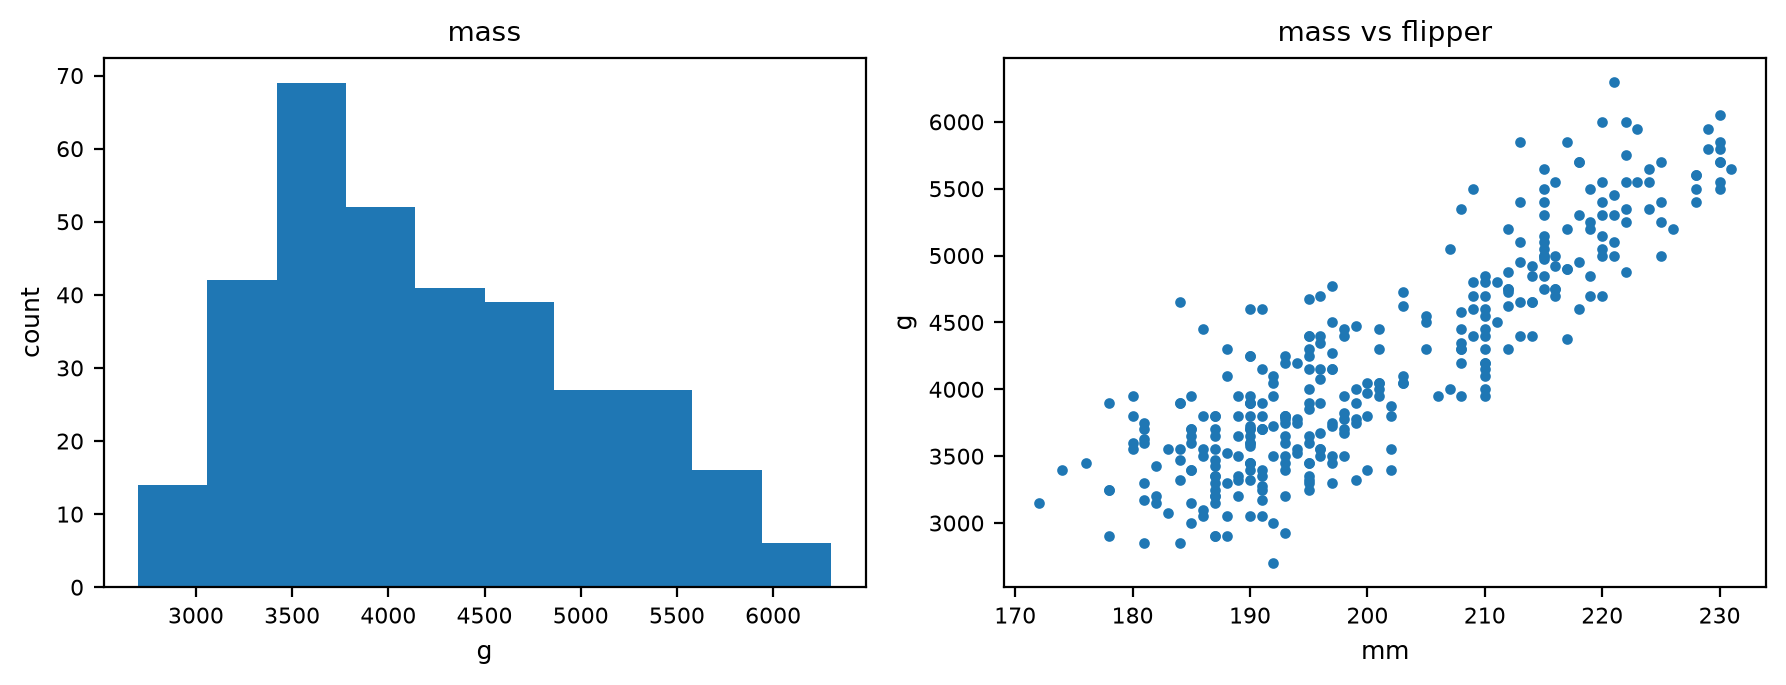

In [885]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].hist(df_complete["body_mass_g"])
axs[0].set(title="mass", xlabel="g", ylabel="count")
axs[1].scatter(df_complete["flipper_length_mm"], df_complete["body_mass_g"], s=8)
axs[1].set(title="mass vs flipper", xlabel="mm", ylabel="g")
plt.tight_layout();

*See also:* Adding a title and axis labels (C1) · Adding an overall title and tight layout (C2) · Choosing between `plt` and `ax` (C1)

#### Shading an area

**C2.16**

`plt.fill_between(x, y, alpha=0.3)`

***(non-examinable)***

The `plt.fill_between()` function allows us to shade the area under a curve. It is useful for showing a tail probability or a confidence band. Alternatively, `plt.axvspan` shades a vertical strip.

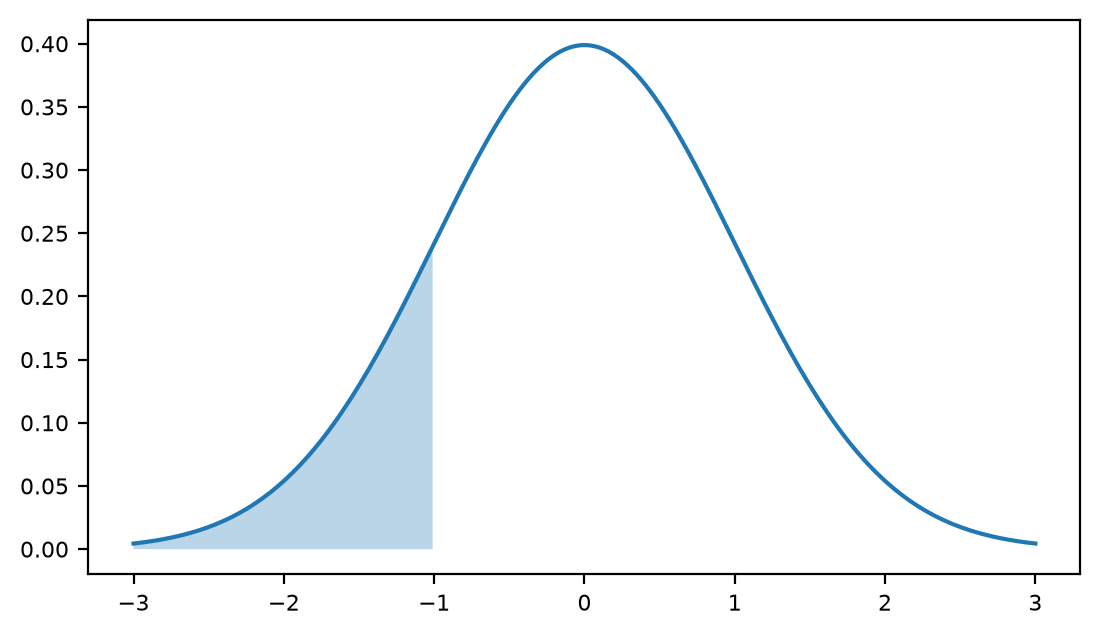

In [886]:
xs = np.linspace(-3, 3, 200)
plt.plot(xs, stats.norm.pdf(xs))
plt.fill_between(xs, stats.norm.pdf(xs), where=xs < -1, alpha=0.3);

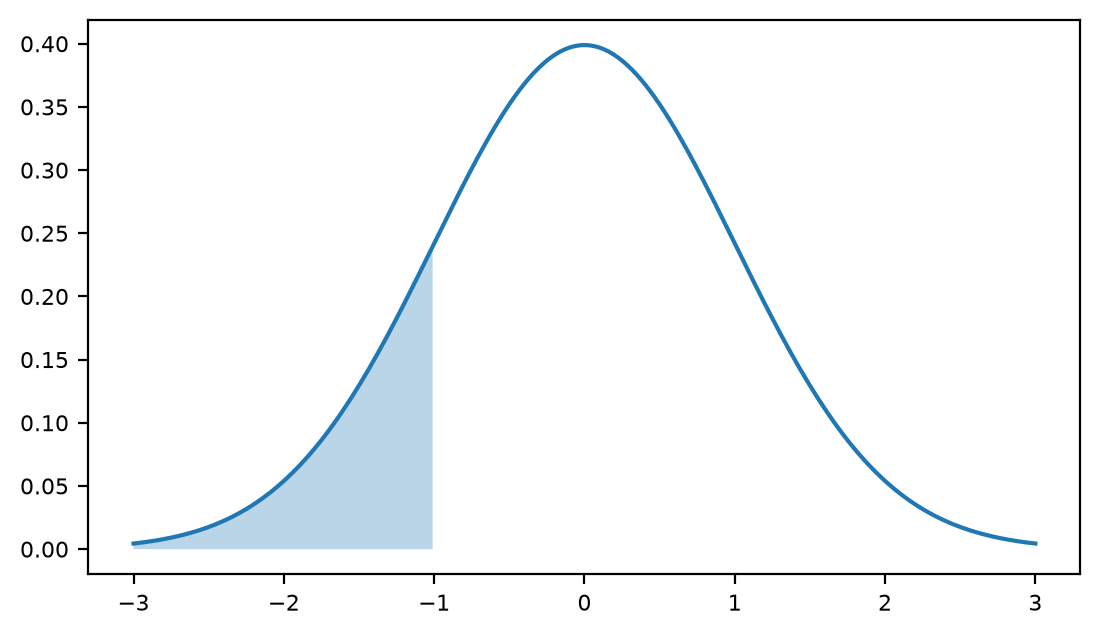

In [887]:
# the same plot in object-oriented style (ax. methods)
xs = np.linspace(-3, 3, 200)
fig, ax = plt.subplots()
ax.plot(xs, stats.norm.pdf(xs))
ax.fill_between(xs, stats.norm.pdf(xs), where=xs < -1, alpha=0.3);

*See also:* Shading a tail of a distribution (D2) · Shading a period (B8) · Drawing error bars (C2) · Drawing a line plot (C3)

#### Drawing error bars

**C2.17**

`plt.errorbar(x, y, yerr=err)`

***(non-examinable)***

The `plt.errorbar()` function allows us to draw points with bars showing their uncertainty. It is useful for means with standard errors or confidence intervals. Alternatively, `sns.barplot` and `sns.pointplot` add intervals automatically.

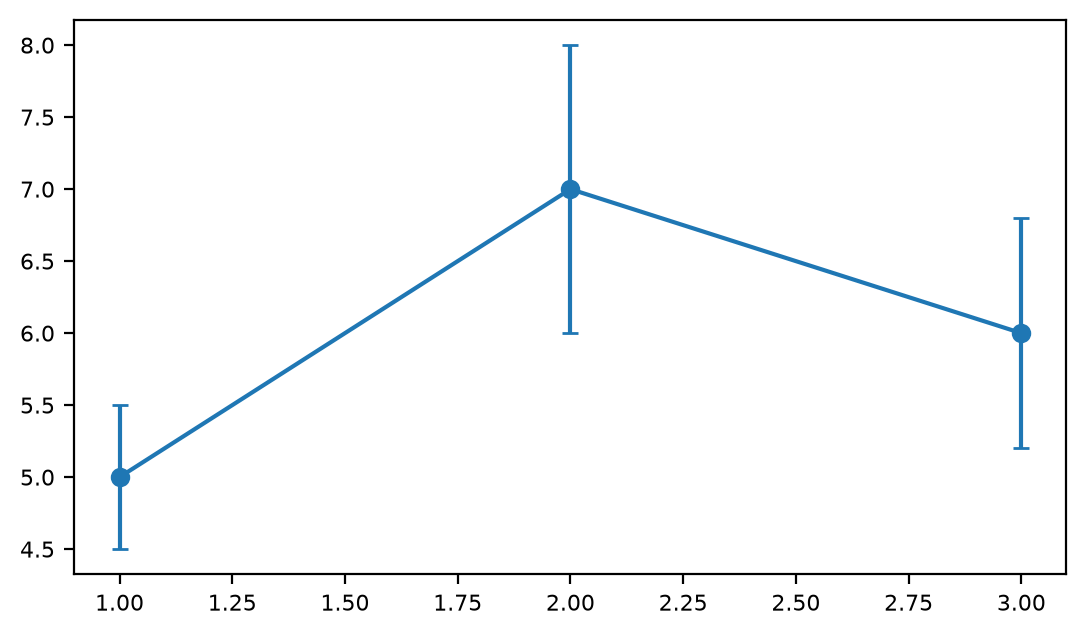

In [888]:
x = [1, 2, 3]
y = [5, 7, 6]
err = [0.5, 1, 0.8]
plt.errorbar(x, y, yerr=err, fmt="o-", capsize=3);

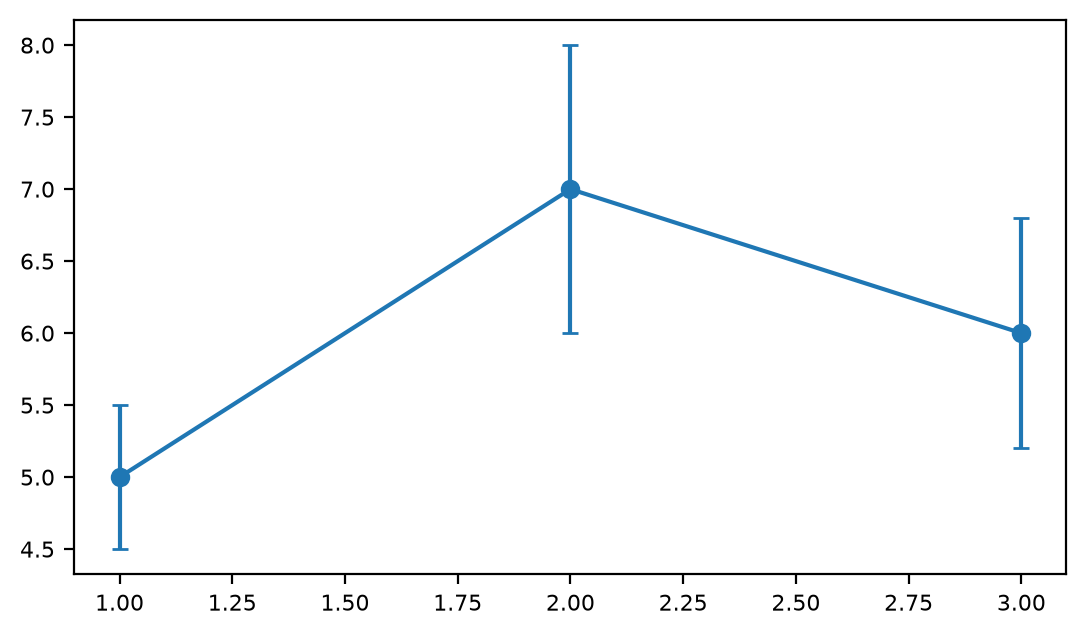

In [889]:
# the same plot in object-oriented style (ax. methods)
x = [1, 2, 3]
y = [5, 7, 6]
err = [0.5, 1, 0.8]
fig, ax = plt.subplots()
ax.errorbar(x, y, yerr=err, fmt="o-", capsize=3);

*See also:* Drawing a bar plot of values (C3) · Drawing panels with `plt.subplot` (C2) · Calculating several statistics per group (B9)